
# Task 05 – Machine Learning Classification Model

## Project Overview
This project develops machine learning classification models
to predict whether a Netflix title is a Movie or TV Show.

## Objectives
- Prepare relevant features.
- Split data into training and testing sets.
- Train classification algorithms.
- Evaluate model performance.
- Compare classification accuracy.

## Algorithms
- Logistic Regression
- Random Forest Classifier

## Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn.


In [22]:

# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib
import os

print("All libraries imported successfully!")


All libraries imported successfully!


In [23]:

# Step 2: Load the cleaned Netflix dataset

data_path = r"D:\aiml and datascience\Auspify-Data-Science-Internship\Task-01-Data-Cleaning\data\processed\netflix_cleaned.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (8790, 15)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit,date_added_year,date_added_month,date_added_month_name
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min,2021,9,September
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season,2021,9,September
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season,2021,9,September
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min,2021,9,September
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min,2021,9,September


In [24]:

# Step 3: Explore the dataset

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nContent Type Distribution:")
print(df["type"].value_counts())

print("\nDataset Preview:")
display(df.head())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   show_id                8790 non-null   object
 1   type                   8790 non-null   object
 2   title                  8790 non-null   object
 3   director               8790 non-null   object
 4   country                8790 non-null   object
 5   date_added             8790 non-null   object
 6   release_year           8790 non-null   int64 
 7   rating                 8790 non-null   object
 8   duration               8790 non-null   object
 9   listed_in              8790 non-null   object
 10  duration_value         8790 non-null   int64 
 11  duration_unit          8790 non-null   object
 12  date_added_year        8790 non-null   int64 
 13  date_added_month       8790 non-null   int64 
 14  date_added_month_name  8790 non-null   object
dtype

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit,date_added_year,date_added_month,date_added_month_name
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min,2021,9,September
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season,2021,9,September
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season,2021,9,September
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min,2021,9,September
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min,2021,9,September


In [25]:

# Step 4: Select features and target

features = [
    "release_year",
    "rating",
    "country",
    "listed_in",
    "date_added_year",
    "date_added_month"
]

X = df[features]
y = df["type"]

print("Input features:")
print(X.head())

print("\nTarget variable:")
print(y.head())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)


Input features:
   release_year rating        country  \
0          2020  PG-13  United States   
1          2021  TV-MA         France   
2          2021  TV-MA  United States   
3          2021  TV-PG         Brazil   
4          1993  TV-MA  United States   

                                           listed_in  date_added_year  \
0                                      Documentaries             2021   
1  Crime TV Shows, International TV Shows, TV Act...             2021   
2                 TV Dramas, TV Horror, TV Mysteries             2021   
3                 Children & Family Movies, Comedies             2021   
4   Dramas, Independent Movies, International Movies             2021   

   date_added_month  
0                 9  
1                 9  
2                 9  
3                 9  
4                 9  

Target variable:
0      Movie
1    TV Show
2    TV Show
3      Movie
4      Movie
Name: type, dtype: object

Feature shape: (8790, 6)
Target shape: (8790,)


In [26]:

# Step 5: Separate numerical and categorical features

numeric_features = [
    "release_year",
    "date_added_year",
    "date_added_month"
]

categorical_features = [
    "rating",
    "country",
    "listed_in"
]

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['release_year', 'date_added_year', 'date_added_month']

Categorical Features:
['rating', 'country', 'listed_in']


In [27]:

# Step 6: Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())


Training Features Shape: (7032, 6)
Testing Features Shape: (1758, 6)

Training Target Distribution:
type
Movie      4901
TV Show    2131
Name: count, dtype: int64

Testing Target Distribution:
type
Movie      1225
TV Show     533
Name: count, dtype: int64


In [28]:

# Step 7: Preprocessing pipelines

# Numerical data preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical data preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [29]:

# Step 8: Train Logistic Regression model

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [30]:

# Step 9: Evaluate Logistic Regression

# Predict using test data
lr_predictions = logistic_model.predict(X_test)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Evaluation")
print("--------------------------------")
print("Accuracy:", round(lr_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))

# Confusion matrix
lr_cm = confusion_matrix(
    y_test,
    lr_predictions,
    labels=["Movie", "TV Show"]
)

print("\nConfusion Matrix:")
print(lr_cm)


Logistic Regression Evaluation
--------------------------------
Accuracy: 99.26 %

Classification Report:
              precision    recall  f1-score   support

       Movie       0.99      1.00      0.99      1225
     TV Show       0.99      0.98      0.99       533

    accuracy                           0.99      1758
   macro avg       0.99      0.99      0.99      1758
weighted avg       0.99      0.99      0.99      1758


Confusion Matrix:
[[1221    4]
 [   9  524]]


In [31]:

# Step 10: Train Random Forest Classifier

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [32]:

# Step 11: Evaluate Random Forest

# Predict using test data
rf_predictions = random_forest_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Evaluation")
print("-------------------------")
print("Accuracy:", round(rf_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

# Confusion matrix
rf_cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=["Movie", "TV Show"]
)

print("\nConfusion Matrix:")
print(rf_cm)


Random Forest Evaluation
-------------------------
Accuracy: 96.99 %

Classification Report:
              precision    recall  f1-score   support

       Movie       0.97      0.99      0.98      1225
     TV Show       0.97      0.93      0.95       533

    accuracy                           0.97      1758
   macro avg       0.97      0.96      0.96      1758
weighted avg       0.97      0.97      0.97      1758


Confusion Matrix:
[[1207   18]
 [  35  498]]


Model Performance Comparison:


,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.992605,99.26
1,Random Forest,0.969852,96.99


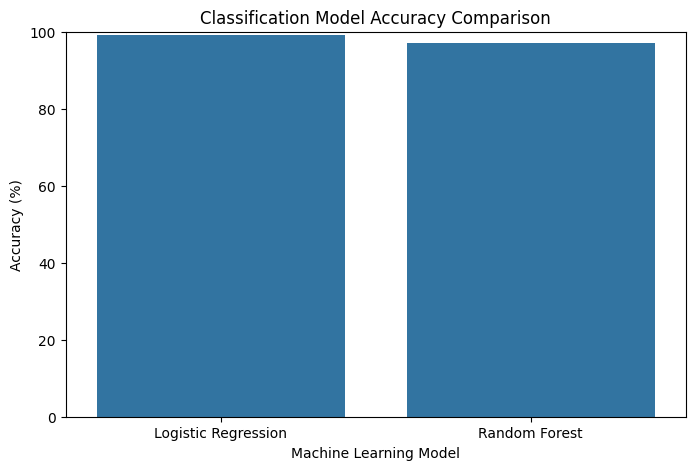

In [33]:

# Step 12: Compare both classification models

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [lr_accuracy, rf_accuracy]
})

model_comparison["Accuracy (%)"] = (
    model_comparison["Accuracy"] * 100
).round(2)

print("Model Performance Comparison:")
display(model_comparison)

# Visualize accuracy comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Classification Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 100)

plt.show()


In [34]:

# Step 13: Save trained models

output_dir = r"Task-05-Classification-Model\outputs"

os.makedirs(output_dir, exist_ok=True)

# Save Logistic Regression model
joblib.dump(
    logistic_model,
    os.path.join(output_dir, "logistic_regression_model.pkl")
)

# Save Random Forest model
joblib.dump(
    random_forest_model,
    os.path.join(output_dir, "random_forest_model.pkl")
)

print("Both trained models saved successfully!")


Both trained models saved successfully!


In [35]:

# Step 14: Save evaluation results

# Save model comparison
model_comparison.to_csv(
    os.path.join(output_dir, "model_comparison.csv"),
    index=False
)

# Save prediction results
prediction_results = pd.DataFrame({
    "Actual": y_test.values,
    "Logistic_Regression_Prediction": lr_predictions,
    "Random_Forest_Prediction": rf_predictions
})

prediction_results.to_csv(
    os.path.join(output_dir, "prediction_results.csv"),
    index=False
)

# Save classification reports
lr_report = pd.DataFrame(
    classification_report(
        y_test,
        lr_predictions,
        output_dict=True
    )
).transpose()

rf_report = pd.DataFrame(
    classification_report(
        y_test,
        rf_predictions,
        output_dict=True
    )
).transpose()

lr_report.to_csv(
    os.path.join(output_dir, "logistic_regression_report.csv")
)

rf_report.to_csv(
    os.path.join(output_dir, "random_forest_report.csv")
)

# Save confusion matrices
pd.DataFrame(
    lr_cm,
    index=["Actual Movie", "Actual TV Show"],
    columns=["Predicted Movie", "Predicted TV Show"]
).to_csv(
    os.path.join(output_dir, "logistic_confusion_matrix.csv")
)

pd.DataFrame(
    rf_cm,
    index=["Actual Movie", "Actual TV Show"],
    columns=["Predicted Movie", "Predicted TV Show"]
).to_csv(
    os.path.join(output_dir, "random_forest_confusion_matrix.csv")
)

print("All evaluation results saved successfully!")


All evaluation results saved successfully!


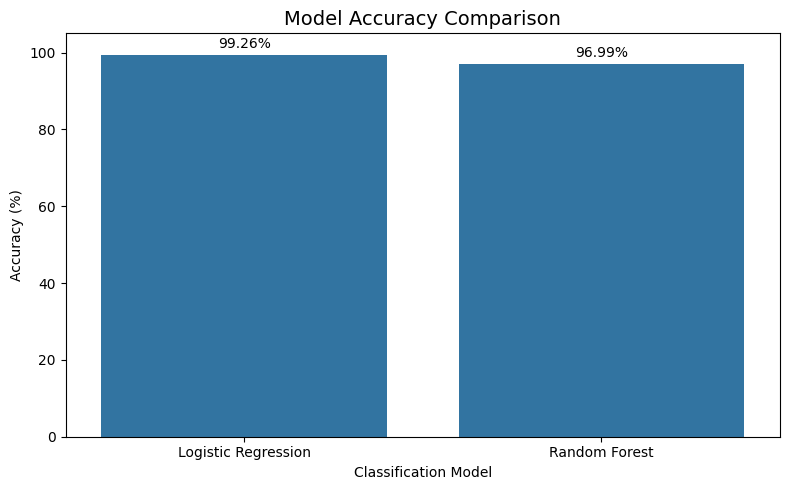

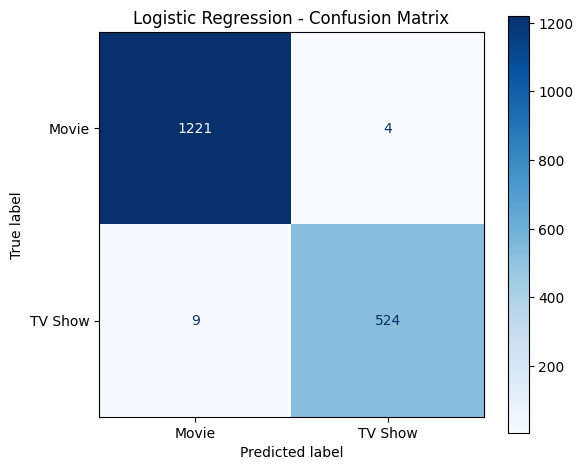

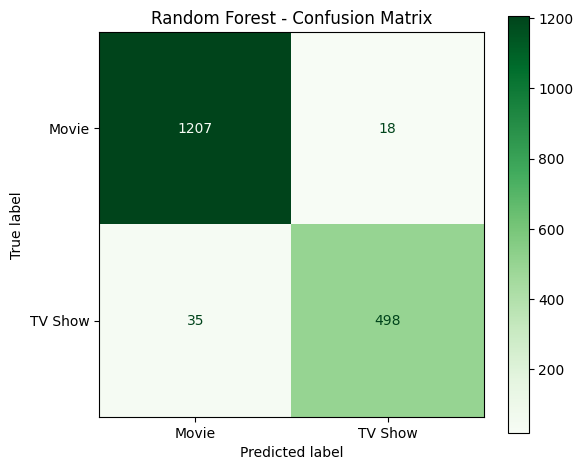

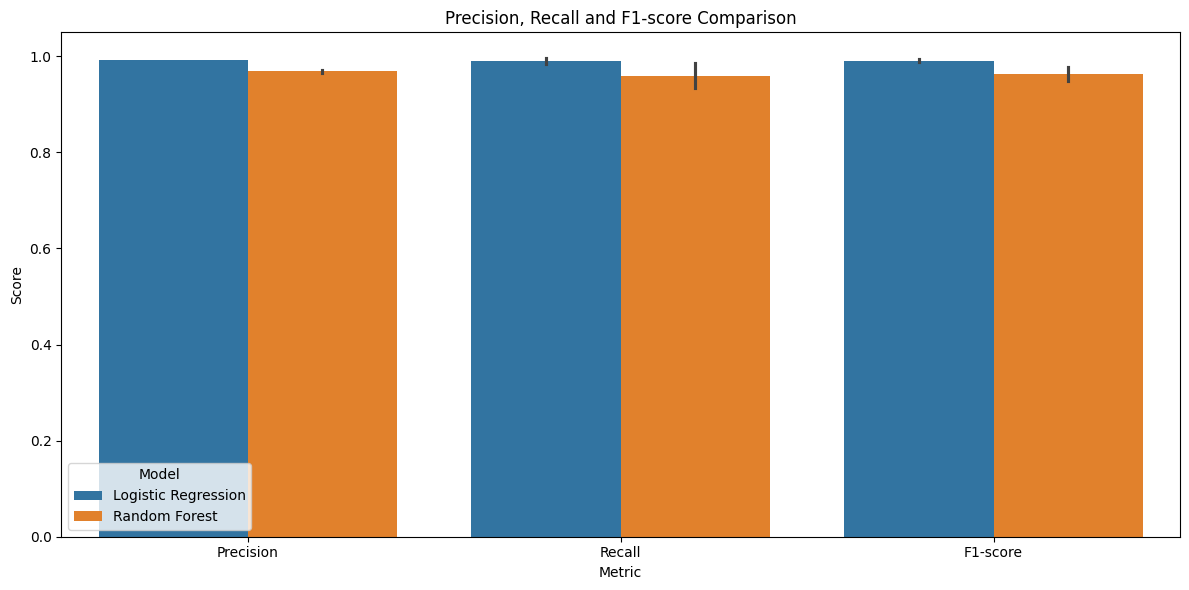

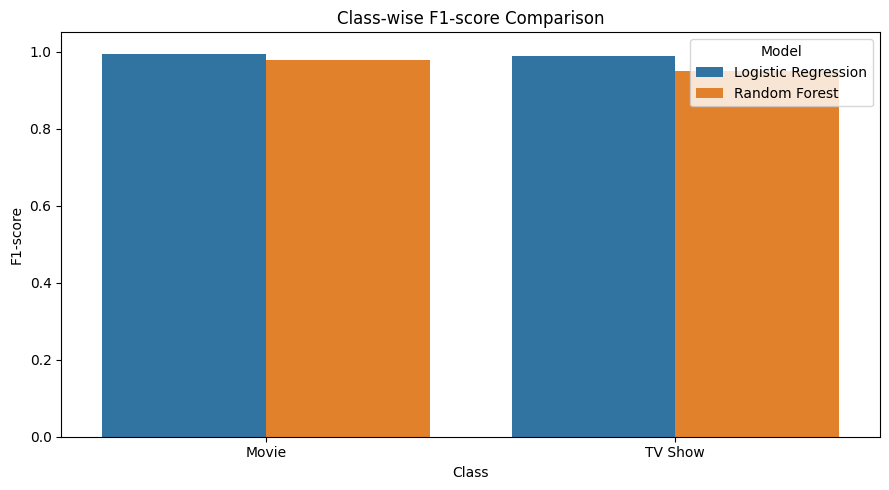

All evaluation visualizations saved successfully!


In [36]:

# Step 15: Create evaluation visualizations

# Make sure output directory exists
os.makedirs(output_dir, exist_ok=True)

# 1. Model Accuracy Comparison
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Model Accuracy Comparison", fontsize=14)
plt.ylabel("Accuracy (%)")
plt.xlabel("Classification Model")
plt.ylim(0, 105)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "model_accuracy_comparison.png"),
    dpi=300
)
plt.show()


# 2. Logistic Regression Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=lr_cm,
    display_labels=["Movie", "TV Show"]
).plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "logistic_confusion_matrix.png"),
    dpi=300
)
plt.show()


# 3. Random Forest Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["Movie", "TV Show"]
).plot(
    cmap="Greens",
    values_format="d",
    ax=ax
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "random_forest_confusion_matrix.png"),
    dpi=300
)
plt.show()


# 4. Precision, Recall and F1-score Comparison
lr_metrics = classification_report(
    y_test, lr_predictions, output_dict=True
)

rf_metrics = classification_report(
    y_test, rf_predictions, output_dict=True
)

metrics_data = []

for model_name, report in [
    ("Logistic Regression", lr_metrics),
    ("Random Forest", rf_metrics)
]:
    for class_name in ["Movie", "TV Show"]:
        for metric in ["precision", "recall", "f1-score"]:
            metrics_data.append({
                "Model": model_name,
                "Class": class_name,
                "Metric": metric.capitalize(),
                "Score": report[class_name][metric]
            })

metrics_df = pd.DataFrame(metrics_data)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=metrics_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Precision, Recall and F1-score Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "classification_metrics_comparison.png"),
    dpi=300
)
plt.show()


# 5. Class-wise F1-score Comparison
f1_data = metrics_df[metrics_df["Metric"] == "F1-score"]

plt.figure(figsize=(9, 5))

sns.barplot(
    data=f1_data,
    x="Class",
    y="Score",
    hue="Model"
)

plt.title("Class-wise F1-score Comparison")
plt.ylabel("F1-score")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "classwise_f1_comparison.png"),
    dpi=300
)
plt.show()


print("All evaluation visualizations saved successfully!")


In [37]:

# Step 16: Final Model Performance Summary

final_summary = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy (%)": [
        round(lr_accuracy * 100, 2),
        round(rf_accuracy * 100, 2)
    ],
    "Movie F1-score": [
        round(lr_metrics["Movie"]["f1-score"], 4),
        round(rf_metrics["Movie"]["f1-score"], 4)
    ],
    "TV Show F1-score": [
        round(lr_metrics["TV Show"]["f1-score"], 4),
        round(rf_metrics["TV Show"]["f1-score"], 4)
    ]
})

display(final_summary)

# Identify the model with higher test accuracy
best_model = final_summary.loc[
    final_summary["Accuracy (%)"].idxmax(),
    "Model"
]

print("\nBest performing model:", best_model)

# Save final summary
final_summary.to_csv(
    os.path.join(output_dir, "final_model_summary.csv"),
    index=False
)

print("\nFinal model summary saved successfully!")


,Model,Accuracy (%),Movie F1-score,TV Show F1-score
0,Logistic Regression,99.26,0.9947,0.9877
1,Random Forest,96.99,0.9785,0.9495



Best performing model: Logistic Regression


OSError: Cannot save file into a non-existent directory: 'Task-05-Classification-Model\outputs'

In [38]:
# Correct output directory using an absolute path

output_dir = r"D:\aiml and datascience\Auspify-Data-Science-Internship\Task-05-Classification-Model\outputs"

os.makedirs(output_dir, exist_ok=True)

print("Output directory:", output_dir)
print("Directory exists:", os.path.exists(output_dir))

Output directory: D:\aiml and datascience\Auspify-Data-Science-Internship\Task-05-Classification-Model\outputs
Directory exists: True


In [39]:
final_summary.to_csv(
    os.path.join(output_dir, "final_model_summary.csv"),
    index=False
)

print("Final model summary saved successfully!")

Final model summary saved successfully!


In [40]:

# Verify all Task 5 output files

print("TASK 5 - OUTPUT FILE VERIFICATION")
print("=" * 50)

for file in sorted(os.listdir(output_dir)):
    file_path = os.path.join(output_dir, file)

    if os.path.isfile(file_path):
        size_kb = os.path.getsize(file_path) / 1024
        print(f"{file:<45} {size_kb:>10.2f} KB")

print("=" * 50)
print("Total output files:", len(os.listdir(output_dir)))


TASK 5 - OUTPUT FILE VERIFICATION
classification_metrics_comparison.png             102.12 KB
classwise_f1_comparison.png                        84.07 KB
final_model_summary.csv                             0.12 KB
logistic_confusion_matrix.csv                       0.08 KB
logistic_confusion_matrix.png                      83.00 KB
logistic_regression_model.pkl                      34.81 KB
logistic_regression_report.csv                      0.41 KB
model_accuracy_comparison.png                      90.73 KB
model_comparison.csv                                0.11 KB
prediction_results.csv                             35.76 KB
random_forest_confusion_matrix.csv                  0.08 KB
random_forest_confusion_matrix.png                 84.70 KB
random_forest_model.pkl                         17385.45 KB
random_forest_report.csv                            0.41 KB
Total output files: 14
